
# E4 — ERM vs GroupDRO + Threshold Adaptation

## Scientific objective

E0–E3 showed that population shift produced only a modest loss in rank discrimination, while threshold-dependent sensitivity differed substantially across `Student_Type`. E3 further showed that post-hoc calibration did not consistently solve this problem.

E4 therefore asks:

> **Is the population gap primarily a learning-objective problem, or can it be explained and reduced by decision-threshold adaptation?**

## Models

Both models use the **same group-blind linear logistic architecture** and the same leakage-safe preprocessing.

1. **ERM Logistic** — minimizes average binary cross-entropy.
2. **GroupDRO Logistic** — minimizes an adaptive weighted combination of group-specific losses, emphasizing the currently worst training groups.

`Student_Type` is **never used as a predictor**. For GroupDRO it is used only as a training-domain label.

## Main deployment policies

- **ERM@0.50**
- **ERM@TrainRecall80** — threshold selected only from 3-fold OOF predictions within the LOSO training populations.
- **GroupDRO@0.50**
- **GroupDRO@TrainRecall80**

Target:

\[
Recall \ge 0.80
\]

The training-OOF threshold is selected as the **largest threshold** that still satisfies the recall constraint, which preferentially preserves specificity.

## Oracle diagnostic

For scientific attribution only, E4 also reports a **HeldoutOracleRecall80** threshold chosen using labels from the held-out population itself.

This oracle is **not deployable and must never be presented as a valid external-validation method**. It estimates the upper bound of what threshold adaptation alone could recover if the target-population labels were known.

## Primary evaluation

Leave-One-Student-Type-Out (LOSO):
- train on two populations,
- test on the third unseen population,
- rotate across school, college, and working_student.

This directly extends E2.


In [1]:

from pathlib import Path
import platform, json, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, brier_score_loss,
    log_loss, matthews_corrcoef, confusion_matrix, precision_recall_curve
)
from scipy.special import expit

SEED = 42
TARGET = "Stress_Level"
GROUP = "Student_Type"
INNER_SPLITS = 3
TARGET_RECALL = 0.80

EPOCHS = 180
LEARNING_RATE = 0.035
L2 = 1e-4
DRO_ETA = 0.10

DATA_CANDIDATES = [
    Path("/mnt/data/student-lifestyle-and-stress-dataset.csv"),
    Path("../data/student-lifestyle-and-stress-dataset.csv"),
    Path("student-lifestyle-and-stress-dataset.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found. Edit DATA_PATH.")

RESULT_DIR = Path("../outputs/E4")
RESULT_DIR.mkdir(exist_ok=True)

np.random.seed(SEED)

print("Python :", platform.python_version())
print("pandas :", pd.__version__)
print("sklearn:", sklearn.__version__)
print("Dataset:", DATA_PATH.resolve())
print("Target recall:", TARGET_RECALL)
print("Inner threshold CV:", INNER_SPLITS)


Python : 3.13.5
pandas : 2.2.3
sklearn: 1.8.0
Dataset: /mnt/data/student-lifestyle-and-stress-dataset.csv
Target recall: 0.8
Inner threshold CV: 3


In [2]:

df = pd.read_csv(DATA_PATH)

NUMERIC_FEATURES = [
    "Sleep_Hours",
    "Study_Hours",
    "Social_Media_Hours",
    "Attendance",
    "Exam_Pressure",
    "Family_Support",
]
CATEGORICAL_FEATURES = ["Month"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

e4_df = df[df[GROUP].notna()].copy().reset_index(drop=False).rename(columns={"index": "original_row_id"})
groups = sorted(e4_df[GROUP].unique().tolist())

print("Full dataset:", df.shape)
print("E4 rows with known Student_Type:", len(e4_df))
print("Excluded missing Student_Type:", int(df[GROUP].isna().sum()))
print("Groups:", groups)


Full dataset: (25500, 9)
E4 rows with known Student_Type: 24248
Excluded missing Student_Type: 1252
Groups: ['college', 'school', 'working_student']



# Leakage-safe preprocessing

The preprocessor is fitted separately inside every inner training fold and again on the full LOSO training set.

- numeric: median imputation + standardization;
- `Month`: most-frequent imputation + one-hot encoding;
- `Student_Type`: excluded from predictors.


In [3]:

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), NUMERIC_FEATURES),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), CATEGORICAL_FEATURES),
    ], sparse_threshold=0)

def fit_transform_train_test(train_df, test_df):
    prep = make_preprocessor()
    X_train = prep.fit_transform(train_df[FEATURES]).astype(np.float64)
    X_test = prep.transform(test_df[FEATURES]).astype(np.float64)
    return X_train, X_test, prep



# Common Logistic Model: ERM and GroupDRO

A custom NumPy implementation is used so both objectives share exactly the same model class, initialization, optimizer, regularization, and preprocessing.

### ERM

\[
L_{ERM} = \frac{1}{N}\sum_i \ell_i
\]

### GroupDRO

For training group \(g\):

\[
L_g = \frac{1}{N_g}\sum_{i \in g}\ell_i
\]

Adaptive group weights are updated by:

\[
q_g \leftarrow
\frac{q_g\exp(\eta L_g)}
{\sum_j q_j\exp(\eta L_j)}
\]

and the training objective becomes:

\[
L_{DRO}=\sum_g q_gL_g
\]

Thus groups with persistently larger training loss receive increasing optimization weight.


In [4]:

def binary_logloss_from_logits(y, z):
    return np.logaddexp(0.0, z) - y * z

def fit_logistic_objective(
    X, y, group_labels=None, objective="ERM",
    epochs=EPOCHS, lr=LEARNING_RATE, l2=L2,
    dro_eta=DRO_ETA
):
    X = np.asarray(X, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)
    n, d = X.shape

    w = np.zeros(d, dtype=np.float64)
    prevalence = np.clip(y.mean(), 1e-4, 1 - 1e-4)
    b = float(np.log(prevalence / (1 - prevalence)))

    # Adam state
    mw = np.zeros_like(w)
    vw = np.zeros_like(w)
    mb = 0.0
    vb = 0.0
    beta1, beta2, eps_adam = 0.9, 0.999, 1e-8

    group_info = None
    if objective == "GroupDRO":
        g = np.asarray(group_labels).astype(str)
        unique_groups = np.unique(g)
        group_indices = {grp: np.where(g == grp)[0] for grp in unique_groups}
        q = np.ones(len(unique_groups), dtype=np.float64) / len(unique_groups)

    for epoch in range(1, epochs + 1):
        z = X @ w + b
        p = expit(np.clip(z, -35, 35))
        residual = p - y

        if objective == "ERM":
            sample_weights = np.full(n, 1.0 / n)
        elif objective == "GroupDRO":
            losses = binary_logloss_from_logits(y, z)
            group_losses = np.array([
                losses[group_indices[grp]].mean()
                for grp in unique_groups
            ])

            # Stable multiplicative update
            log_q = np.log(np.clip(q, 1e-15, None)) + dro_eta * group_losses
            log_q -= log_q.max()
            q = np.exp(log_q)
            q /= q.sum()

            sample_weights = np.zeros(n, dtype=np.float64)
            for qg, grp in zip(q, unique_groups):
                idx = group_indices[grp]
                sample_weights[idx] = qg / len(idx)
        else:
            raise ValueError("objective must be ERM or GroupDRO")

        grad_w = X.T @ (sample_weights * residual) + l2 * w
        grad_b = float(np.sum(sample_weights * residual))

        # Adam
        mw = beta1 * mw + (1 - beta1) * grad_w
        vw = beta2 * vw + (1 - beta2) * (grad_w ** 2)
        mb = beta1 * mb + (1 - beta1) * grad_b
        vb = beta2 * vb + (1 - beta2) * (grad_b ** 2)

        mw_hat = mw / (1 - beta1 ** epoch)
        vw_hat = vw / (1 - beta2 ** epoch)
        mb_hat = mb / (1 - beta1 ** epoch)
        vb_hat = vb / (1 - beta2 ** epoch)

        w -= lr * mw_hat / (np.sqrt(vw_hat) + eps_adam)
        b -= lr * mb_hat / (np.sqrt(vb_hat) + eps_adam)

    if objective == "GroupDRO":
        group_info = {
            grp: float(qg) for grp, qg in zip(unique_groups, q)
        }

    return {"w": w, "b": b, "group_weights": group_info}

def predict_proba_linear(model, X):
    z = np.asarray(X) @ model["w"] + model["b"]
    return expit(np.clip(z, -35, 35))


# Metrics and threshold selection

In [5]:

def probability_metrics(y_true, prob):
    y = np.asarray(y_true).astype(int)
    p = np.asarray(prob, dtype=float)
    return {
        "roc_auc": roc_auc_score(y, p),
        "pr_auc": average_precision_score(y, p),
        "brier": brier_score_loss(y, p),
        "nll": log_loss(y, p, labels=[0, 1]),
    }

def decision_metrics(y_true, prob, threshold):
    y = np.asarray(y_true).astype(int)
    p = np.asarray(prob, dtype=float)
    pred = (p >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else np.nan

    return {
        "threshold": float(threshold),
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "specificity": specificity,
        "f1": f1_score(y, pred, zero_division=0),
        "mcc": matthews_corrcoef(y, pred),
        "intervention_rate": float(pred.mean()),
        "tp": int(tp),
        "fp": int(fp),
        "tn": int(tn),
        "fn": int(fn),
    }

def select_recall_constrained_threshold(y_true, prob, target_recall=TARGET_RECALL):
    y = np.asarray(y_true).astype(int)
    p = np.asarray(prob, dtype=float)

    precision, recall, thresholds = precision_recall_curve(y, p)
    if len(thresholds) == 0:
        return 0.5

    valid = recall[:-1] >= target_recall
    if not np.any(valid):
        return 0.0

    # Largest threshold satisfying the sensitivity constraint.
    return float(np.max(thresholds[valid]))



# Inner OOF threshold learning

For each LOSO training set and each objective:

1. split the **training populations only** into 3 stratified folds;
2. fit preprocessing and model on each inner training fold;
3. predict its validation fold;
4. pool OOF probabilities;
5. choose the global threshold satisfying `Recall ≥ 0.80`.

No held-out-population observation participates in this threshold selection.


In [6]:

def training_oof_predictions(train_df, objective, seed=SEED):
    y = train_df[TARGET].astype(int).to_numpy()
    g = train_df[GROUP].astype(str).to_numpy()

    cv = StratifiedKFold(
        n_splits=INNER_SPLITS,
        shuffle=True,
        random_state=seed,
    )

    oof = np.full(len(train_df), np.nan)

    for fold, (tr, va) in enumerate(cv.split(train_df, y), start=1):
        inner_train = train_df.iloc[tr]
        inner_valid = train_df.iloc[va]

        X_tr, X_va, _ = fit_transform_train_test(inner_train, inner_valid)

        model = fit_logistic_objective(
            X_tr,
            inner_train[TARGET].astype(int).to_numpy(),
            group_labels=inner_train[GROUP].astype(str).to_numpy(),
            objective=objective,
        )
        oof[va] = predict_proba_linear(model, X_va)

    if np.isnan(oof).any():
        raise RuntimeError("Incomplete OOF predictions.")

    return oof


# E4 LOSO Experiment

In [7]:

OBJECTIVES = ["ERM", "GroupDRO"]

model_rows = []
policy_rows = []
pred_rows = []
threshold_rows = []
dro_weight_rows = []

for heldout in groups:
    train_df = e4_df[e4_df[GROUP] != heldout].copy()
    test_df = e4_df[e4_df[GROUP] == heldout].copy()

    y_train = train_df[TARGET].astype(int).to_numpy()
    y_test = test_df[TARGET].astype(int).to_numpy()

    for objective in OBJECTIVES:
        # ---------- training-only threshold learning ----------
        train_oof_prob = training_oof_predictions(train_df, objective)
        train_threshold = select_recall_constrained_threshold(
            y_train, train_oof_prob, TARGET_RECALL
        )
        train_oof_policy = decision_metrics(
            y_train, train_oof_prob, train_threshold
        )

        # ---------- final model ----------
        X_train, X_test, prep = fit_transform_train_test(train_df, test_df)
        model = fit_logistic_objective(
            X_train,
            y_train,
            group_labels=train_df[GROUP].astype(str).to_numpy(),
            objective=objective,
        )
        test_prob = predict_proba_linear(model, X_test)

        # Non-deployable oracle threshold, for attribution only.
        oracle_threshold = select_recall_constrained_threshold(
            y_test, test_prob, TARGET_RECALL
        )

        threshold_rows.append({
            "heldout_group": heldout,
            "objective": objective,
            "train_oof_threshold_recall80": train_threshold,
            "train_oof_achieved_recall": train_oof_policy["recall"],
            "train_oof_specificity": train_oof_policy["specificity"],
            "heldout_oracle_threshold_recall80": oracle_threshold,
            "oracle_is_deployable": False,
        })

        model_rows.append({
            "heldout_group": heldout,
            "objective": objective,
            "n_train": len(train_df),
            "n_test": len(test_df),
            "train_prevalence": y_train.mean(),
            "test_prevalence": y_test.mean(),
            **probability_metrics(y_test, test_prob),
        })

        policies = {
            "Fixed0.50": (0.50, True),
            "TrainRecall80": (train_threshold, True),
            "HeldoutOracleRecall80": (oracle_threshold, False),
        }

        for policy, (threshold, deployable) in policies.items():
            policy_rows.append({
                "heldout_group": heldout,
                "objective": objective,
                "policy": policy,
                "deployable": deployable,
                "n_test": len(test_df),
                **decision_metrics(y_test, test_prob, threshold),
            })

        for row_id, yt, pr in zip(
            test_df["original_row_id"].to_numpy(),
            y_test,
            test_prob,
        ):
            pred_rows.append({
                "original_row_id": int(row_id),
                "heldout_group": heldout,
                "objective": objective,
                "y_true": int(yt),
                "prob": float(pr),
                "train_threshold_recall80": train_threshold,
                "oracle_threshold_recall80": oracle_threshold,
            })

        if objective == "GroupDRO":
            for train_group, weight in model["group_weights"].items():
                dro_weight_rows.append({
                    "heldout_group": heldout,
                    "training_group": train_group,
                    "final_group_weight": weight,
                })

model_metrics = pd.DataFrame(model_rows)
policy_metrics = pd.DataFrame(policy_rows)
predictions = pd.DataFrame(pred_rows)
thresholds = pd.DataFrame(threshold_rows)
dro_weights = pd.DataFrame(dro_weight_rows)

model_metrics.to_csv(RESULT_DIR / "e4_loso_probability_metrics.csv", index=False)
policy_metrics.to_csv(RESULT_DIR / "e4_loso_policy_metrics.csv", index=False)
predictions.to_csv(RESULT_DIR / "e4_loso_predictions.csv", index=False)
thresholds.to_csv(RESULT_DIR / "e4_thresholds.csv", index=False)
dro_weights.to_csv(RESULT_DIR / "e4_groupdro_final_group_weights.csv", index=False)

display(model_metrics.round(5))
display(thresholds.round(5))
display(dro_weights.round(5))


,heldout_group,objective,n_train,n_test,train_prevalence,test_prevalence,roc_auc,pr_auc,brier,nll
0,college,ERM,10857,13391,0.28369,0.31252,0.86184,0.75098,0.13428,0.42112
1,college,GroupDRO,10857,13391,0.28369,0.31252,0.86171,0.75055,0.13446,0.42127
2,school,ERM,18227,6021,0.33094,0.20478,0.85467,0.64608,0.10989,0.35640
3,school,GroupDRO,18227,6021,0.33094,0.20478,0.85398,0.64433,0.11024,0.35737
4,working_student,ERM,19412,4836,0.27911,0.38193,0.85980,0.80485,0.14510,0.44780
5,working_student,GroupDRO,19412,4836,0.27911,0.38193,0.85997,0.80506,0.14502,0.44753


,heldout_group,objective,train_oof_threshold_recall80,train_oof_achieved_recall,train_oof_specificity,heldout_oracle_threshold_recall80,oracle_is_deployable
0,college,ERM,0.27077,0.80000,0.77253,0.29716,False
1,college,GroupDRO,0.27857,0.80000,0.77163,0.30168,False
2,school,ERM,0.31299,0.80007,0.76080,0.19219,False
3,school,GroupDRO,0.31605,0.80007,0.76105,0.19247,False
4,working_student,ERM,0.27245,0.80011,0.77083,0.34011,False
5,working_student,GroupDRO,0.27515,0.80011,0.77197,0.34121,False


,heldout_group,training_group,final_group_weight
0,college,school,0.15443
1,college,working_student,0.84557
2,school,college,0.39028
3,school,working_student,0.60972
4,working_student,college,0.77812
5,working_student,school,0.22188


# Aggregate deployable-policy comparison

In [8]:

deployable = policy_metrics[policy_metrics["deployable"]].copy()

aggregate_rows = []
for (objective, policy), part in deployable.groupby(["objective", "policy"]):
    weights = part["n_test"] / part["n_test"].sum()

    pooled_pred_parts = []
    for heldout in groups:
        pred_part = predictions[
            (predictions["objective"] == objective) &
            (predictions["heldout_group"] == heldout)
        ].copy()

        if policy == "Fixed0.50":
            threshold = 0.50
        elif policy == "TrainRecall80":
            threshold = float(
                thresholds[
                    (thresholds["objective"] == objective) &
                    (thresholds["heldout_group"] == heldout)
                ]["train_oof_threshold_recall80"].iloc[0]
            )
        else:
            continue

        pred_part["decision"] = (
            pred_part["prob"] >= threshold
        ).astype(int)
        pooled_pred_parts.append(pred_part)

    pooled = pd.concat(pooled_pred_parts, ignore_index=True)
    y_pool = pooled["y_true"].to_numpy()
    d_pool = pooled["decision"].to_numpy()
    tn, fp, fn, tp = confusion_matrix(
        y_pool, d_pool, labels=[0, 1]
    ).ravel()

    aggregate_rows.append({
        "objective": objective,
        "policy": policy,
        "weighted_recall": np.sum(weights * part["recall"]),
        "worst_group_recall": part["recall"].min(),
        "best_group_recall": part["recall"].max(),
        "recall_gap": part["recall"].max() - part["recall"].min(),
        "weighted_specificity": np.sum(weights * part["specificity"]),
        "worst_group_specificity": part["specificity"].min(),
        "weighted_balanced_accuracy": np.sum(
            weights * part["balanced_accuracy"]
        ),
        "weighted_precision": np.sum(weights * part["precision"]),
        "weighted_intervention_rate": np.sum(
            weights * part["intervention_rate"]
        ),
        "pooled_recall": tp / (tp + fn),
        "pooled_specificity": tn / (tn + fp),
        "pooled_precision": tp / (tp + fp) if (tp + fp) else np.nan,
        "pooled_intervention_rate": d_pool.mean(),
        "pooled_false_negatives": int(fn),
        "pooled_false_positives": int(fp),
    })

aggregate = pd.DataFrame(aggregate_rows).sort_values(
    ["policy", "objective"]
)
display(aggregate.round(5))
aggregate.to_csv(
    RESULT_DIR / "e4_deployable_policy_aggregate.csv",
    index=False
)


,objective,policy,weighted_recall,worst_group_recall,best_group_recall,recall_gap,weighted_specificity,worst_group_specificity,weighted_balanced_accuracy,weighted_precision,weighted_intervention_rate,pooled_recall,pooled_specificity,pooled_precision,pooled_intervention_rate,pooled_false_negatives,pooled_false_positives
0,ERM,Fixed0.50,0.59174,0.47770,0.68706,0.20936,0.90220,0.86049,0.74697,0.72389,0.24852,0.60633,0.90455,0.73100,0.24852,2860,1621
2,GroupDRO,Fixed0.50,0.59346,0.47770,0.68706,0.20936,0.89990,0.85948,0.74668,0.72014,0.25062,0.60812,0.90231,0.72700,0.25062,2847,1659
1,ERM,TrainRecall80,0.79599,0.69019,0.85111,0.16092,0.75649,0.67916,0.77624,0.58745,0.40882,0.80798,0.76194,0.59215,0.40882,1395,4043
3,GroupDRO,TrainRecall80,0.79238,0.68694,0.84894,0.16200,0.75893,0.68183,0.77565,0.58890,0.40605,0.80440,0.76435,0.59354,0.40605,1421,4002


# Attribution: how much can threshold adaptation recover?

In [9]:

# Compare fixed, training-selected, and oracle recall for every objective/group.
attrib = policy_metrics.pivot_table(
    index=["heldout_group", "objective"],
    columns="policy",
    values=["threshold", "recall", "specificity", "intervention_rate"]
)
attrib.columns = [
    f"{metric}_{policy}" for metric, policy in attrib.columns
]
attrib = attrib.reset_index()

attrib["recall_gain_train_threshold_vs_fixed"] = (
    attrib["recall_TrainRecall80"] -
    attrib["recall_Fixed0.50"]
)
attrib["recall_gain_oracle_vs_fixed"] = (
    attrib["recall_HeldoutOracleRecall80"] -
    attrib["recall_Fixed0.50"]
)
attrib["specificity_cost_train_threshold_vs_fixed"] = (
    attrib["specificity_Fixed0.50"] -
    attrib["specificity_TrainRecall80"]
)
attrib["intervention_increase_train_threshold_vs_fixed"] = (
    attrib["intervention_rate_TrainRecall80"] -
    attrib["intervention_rate_Fixed0.50"]
)

display(attrib.round(5))
attrib.to_csv(
    RESULT_DIR / "e4_threshold_attribution.csv",
    index=False
)


,heldout_group,objective,intervention_rate_Fixed0.50,intervention_rate_HeldoutOracleRecall80,intervention_rate_TrainRecall80,recall_Fixed0.50,recall_HeldoutOracleRecall80,recall_TrainRecall80,specificity_Fixed0.50,specificity_HeldoutOracleRecall80,specificity_TrainRecall80,threshold_Fixed0.50,threshold_HeldoutOracleRecall80,threshold_TrainRecall80,recall_gain_train_threshold_vs_fixed,recall_gain_oracle_vs_fixed,specificity_cost_train_threshold_vs_fixed,intervention_increase_train_threshold_vs_fixed
0,college,ERM,0.25943,0.41155,0.43738,0.60860,0.80000,0.82366,0.89930,0.76504,0.73821,0.5,0.29716,0.27077,0.21505,0.19140,0.16109,0.17796
1,college,GroupDRO,0.26301,0.41416,0.43425,0.61171,0.80000,0.81935,0.89550,0.76124,0.74082,0.5,0.30168,0.27857,0.20765,0.18829,0.15468,0.17123
2,school,ERM,0.14383,0.36921,0.25328,0.47770,0.80049,0.69019,0.94215,0.74185,0.85923,0.5,0.19219,0.31299,0.21249,0.32279,0.08292,0.10945
3,school,GroupDRO,0.14383,0.37253,0.25112,0.47770,0.80049,0.68694,0.94215,0.73768,0.86111,0.5,0.19247,0.31605,0.20925,0.32279,0.08104,0.10729
4,working_student,ERM,0.34864,0.45968,0.52337,0.68706,0.80022,0.85111,0.86049,0.75075,0.67916,0.5,0.34011,0.27245,0.16405,0.11316,0.18133,0.17473
5,working_student,GroupDRO,0.34926,0.45947,0.52089,0.68706,0.80022,0.84894,0.85948,0.75109,0.68183,0.5,0.34121,0.27515,0.16188,0.11316,0.17765,0.17163


# GroupDRO vs ERM probability-level effect

In [10]:

prob_compare = model_metrics.pivot(
    index="heldout_group",
    columns="objective",
    values=["roc_auc", "pr_auc", "brier", "nll"]
)

rows = []
for heldout in groups:
    row = {"heldout_group": heldout}
    for metric in ["roc_auc", "pr_auc", "brier", "nll"]:
        erm = prob_compare.loc[heldout, (metric, "ERM")]
        dro = prob_compare.loc[heldout, (metric, "GroupDRO")]
        row[f"{metric}_ERM"] = erm
        row[f"{metric}_GroupDRO"] = dro
        if metric in ["roc_auc", "pr_auc"]:
            row[f"{metric}_DRO_improvement"] = dro - erm
        else:
            row[f"{metric}_DRO_improvement"] = erm - dro
    rows.append(row)

prob_effect = pd.DataFrame(rows)
display(prob_effect.round(6))
prob_effect.to_csv(
    RESULT_DIR / "e4_groupdro_vs_erm_probability_effect.csv",
    index=False
)


,heldout_group,roc_auc_ERM,roc_auc_GroupDRO,roc_auc_DRO_improvement,pr_auc_ERM,pr_auc_GroupDRO,pr_auc_DRO_improvement,brier_ERM,brier_GroupDRO,brier_DRO_improvement,nll_ERM,nll_GroupDRO,nll_DRO_improvement
0,college,0.861841,0.861709,-0.000132,0.750984,0.750548,-0.000436,0.134278,0.134459,-0.000181,0.421115,0.421271,-0.000156
1,school,0.854671,0.853982,-0.000690,0.646082,0.644328,-0.001755,0.109887,0.110243,-0.000356,0.356402,0.357365,-0.000963
2,working_student,0.859801,0.859971,0.000170,0.804848,0.805062,0.000214,0.145095,0.145020,0.000075,0.447803,0.447533,0.000270


# Figures

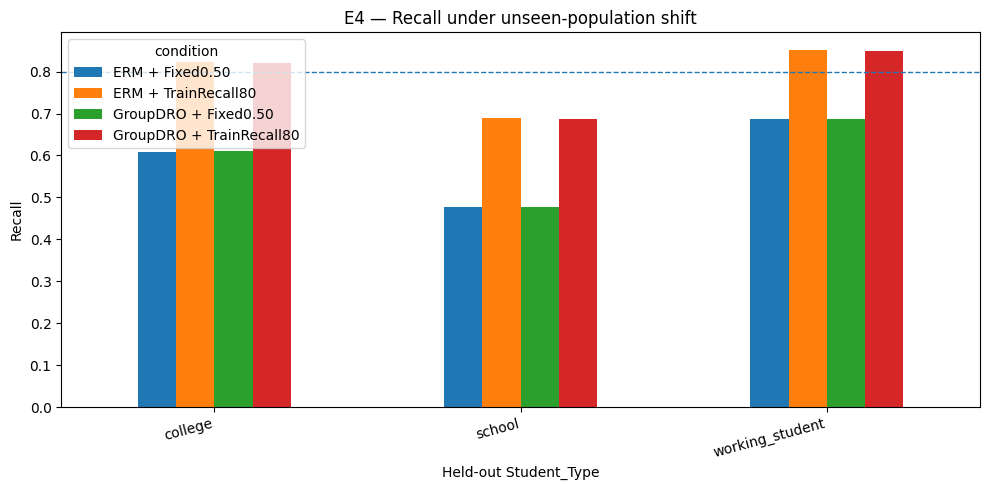

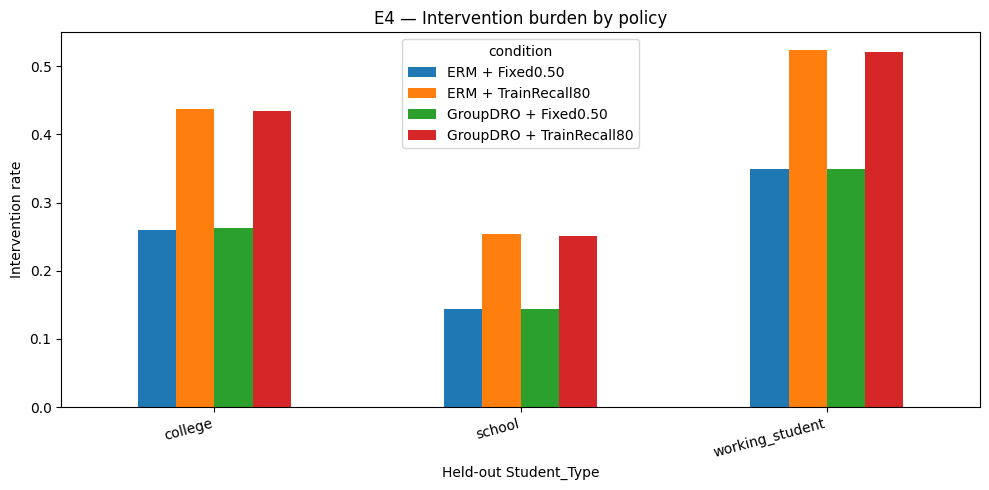

In [11]:

# Deployable recall by held-out group
fig_data = deployable.copy()
fig_data["condition"] = fig_data["objective"] + " + " + fig_data["policy"]

pivot = fig_data.pivot(
    index="heldout_group",
    columns="condition",
    values="recall"
)
ax = pivot.plot(kind="bar", figsize=(10, 5))
ax.axhline(TARGET_RECALL, linestyle="--", linewidth=1)
ax.set_ylabel("Recall")
ax.set_xlabel("Held-out Student_Type")
ax.set_title("E4 — Recall under unseen-population shift")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(
    RESULT_DIR / "fig_e4_recall_by_group_policy.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

# Intervention burden
pivot2 = fig_data.pivot(
    index="heldout_group",
    columns="condition",
    values="intervention_rate"
)
ax = pivot2.plot(kind="bar", figsize=(10, 5))
ax.set_ylabel("Intervention rate")
ax.set_xlabel("Held-out Student_Type")
ax.set_title("E4 — Intervention burden by policy")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(
    RESULT_DIR / "fig_e4_intervention_rate.png",
    dpi=200, bbox_inches="tight"
)
plt.show()


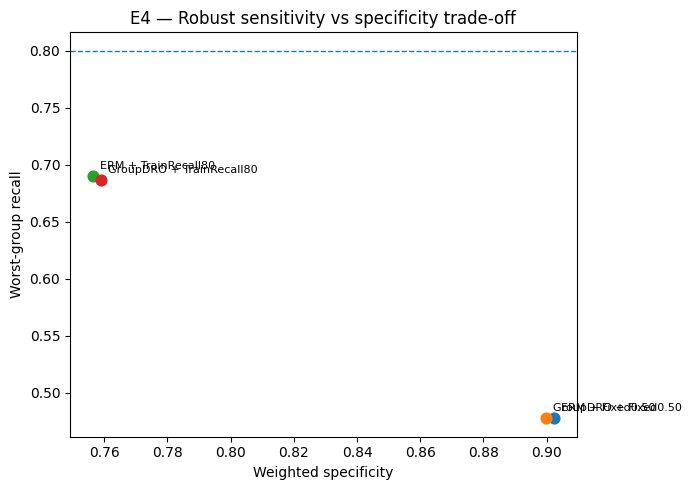

In [12]:

# Worst-group recall vs weighted specificity
fig, ax = plt.subplots(figsize=(7, 5))
for _, row in aggregate.iterrows():
    label = f"{row['objective']} + {row['policy']}"
    ax.scatter(
        row["weighted_specificity"],
        row["worst_group_recall"],
        s=60,
    )
    ax.annotate(
        label,
        (row["weighted_specificity"], row["worst_group_recall"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

ax.axhline(TARGET_RECALL, linestyle="--", linewidth=1)
ax.set_xlabel("Weighted specificity")
ax.set_ylabel("Worst-group recall")
ax.set_title("E4 — Robust sensitivity vs specificity trade-off")
plt.tight_layout()
plt.savefig(
    RESULT_DIR / "fig_e4_worst_recall_vs_specificity.png",
    dpi=200, bbox_inches="tight"
)
plt.show()



# Interpretation Logic

## Evidence for a learning-objective problem

GroupDRO would need to improve one or more of:
- worst-group recall at the same threshold;
- worst-group balanced accuracy;
- PR-AUC / ROC-AUC on held-out populations;
- Brier/NLL;
- recall gap;

without an excessive intervention burden or specificity loss.

## Evidence for a decision-policy problem

If:
- ERM and GroupDRO have almost identical AUC/Brier/NLL,
- but `TrainRecall80` substantially improves worst-group recall,

then the dominant problem is not representation learning. It is **threshold-policy mismatch under differing population base rates / score distributions**.

## Meaning of the oracle

If the oracle threshold greatly exceeds deployable training-threshold performance, there remains target-population information that cannot be recovered from source populations alone.

If training-selected and oracle thresholds perform similarly, threshold adaptation is largely learnable without target labels.

## Important fairness language

Differences in subgroup performance are reported as **population heterogeneity / worst-group reliability**, not as a formal fairness violation. Formal fairness claims would require normative group definitions and a deployment context.


In [13]:

manifest = {
    "experiment": "E4 ERM vs GroupDRO + Threshold Adaptation",
    "dataset_rows_known_group": int(len(e4_df)),
    "excluded_missing_group": int(df[GROUP].isna().sum()),
    "features": FEATURES,
    "group_variable": GROUP,
    "objectives": OBJECTIVES,
    "deployment_policies": ["Fixed0.50", "TrainRecall80"],
    "diagnostic_oracle": "HeldoutOracleRecall80 (non-deployable)",
    "target_recall": TARGET_RECALL,
    "inner_threshold_cv_folds": INNER_SPLITS,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "l2": L2,
    "dro_eta": DRO_ETA,
    "seed": SEED,
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
}

with open(RESULT_DIR / "run_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

print("Saved outputs:")
for p in sorted(RESULT_DIR.glob("*")):
    print("-", p)


Saved outputs:
- student_stress_e4_outputs/e4_deployable_policy_aggregate.csv
- student_stress_e4_outputs/e4_groupdro_final_group_weights.csv
- student_stress_e4_outputs/e4_groupdro_vs_erm_probability_effect.csv
- student_stress_e4_outputs/e4_loso_policy_metrics.csv
- student_stress_e4_outputs/e4_loso_predictions.csv
- student_stress_e4_outputs/e4_loso_probability_metrics.csv
- student_stress_e4_outputs/e4_threshold_attribution.csv
- student_stress_e4_outputs/e4_thresholds.csv
- student_stress_e4_outputs/fig_e4_intervention_rate.png
- student_stress_e4_outputs/fig_e4_recall_by_group_policy.png
- student_stress_e4_outputs/fig_e4_worst_recall_vs_specificity.png
- student_stress_e4_outputs/run_manifest.json
